# LAB | BMI Survey 


## Part 1: Descriptive Analysis

## Problem Description

Overweight and obesity, measured by Body Mass Index (BMI), are increasing health concerns in Denmark and globally. This project analyzes BMI data from a Danish survey to provide an overview of BMI distributions and investigate potential factors influencing BMI, such as gender, age, and fast food consumption. The analysis aims to summarize and visualize the data using descriptive statistics and graphical methods.

---

## Instructions

- Complete each section below using Python and appropriate libraries (e.g., pandas, numpy, matplotlib, seaborn).
- Provide code, tables, and figures as needed.
- Write brief explanations for your findings after each analysis step.
- Do **not** include code in your final report; code should be submitted separately as an appendix.
- Ensure all figures and tables are clearly labeled and referenced in your explanations.

---

## Q1. Data Overview

**a) Short Description of the Data**

- List all variables in the dataset.
- Classify each variable as quantitative or categorical.
- State the number of observations.
- Check for missing values.


**Instructions:**  
- Summarize the dataset variables and their types.
- Report the number of observations and any missing values.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

bmi = pd.read_csv("data/bmi1_data.csv", sep=";")

# Variable types
types = pd.DataFrame({
    "variable": bmi.columns,
    "type": ["quantitative (cm)", "quantitative (kg)", "categorical (0 = female, 1 = male)",
             "categorical / ordinal (city size 1-5)", "quantitative (days per year)"],
    "missing": bmi.isna().sum().values,
})
display(types)
print("Number of observations:", len(bmi))
print("Total missing values:", int(bmi.isna().sum().sum()))

,variable,type,missing
0,height,quantitative (cm),0
1,weight,quantitative (kg),0
2,gender,"categorical (0 = female, 1 = male)",0
3,urbanity,categorical / ordinal (city size 1-5),0
4,fastfood,quantitative (days per year),0


Number of observations: 145
Total missing values: 0


## 2. Calculating BMI

- Compute BMI for each respondent using the formula:

  $$\text{BMI} = \frac{\text{weight (kg)}}{\left[\text{height (m)}\right]^2}$$

- Add BMI as a new column to the dataset.

---


In [2]:
bmi["bmi"] = bmi["weight"] / (bmi["height"] / 100) ** 2
bmi["bmi"].describe().round(2)

count    145.00
mean      25.25
std        3.83
min       17.58
25%       22.59
50%       24.69
75%       27.64
max       39.52
Name: bmi, dtype: float64


## 3. Empirical Distribution of BMI

**b) Density Histogram of BMI Scores**

- Plot a density histogram of BMI.
- Describe the distribution: symmetry, skewness, possible negative values, and variation.

**Instructions:**  
- Comment on the shape and spread of the BMI distribution.

---


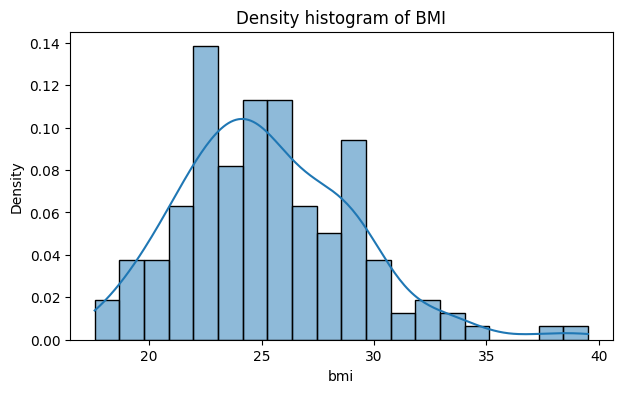

Skewness: 0.66 | min: 17.6 | max: 39.5 | sd: 3.83


In [3]:
plt.figure(figsize=(7, 4))
sns.histplot(bmi["bmi"], stat="density", bins=20, kde=True)
plt.title("Density histogram of BMI")
plt.show()
print(f"Skewness: {stats.skew(bmi['bmi']):.2f} | min: {bmi['bmi'].min():.1f} | max: {bmi['bmi'].max():.1f} | sd: {bmi['bmi'].std():.2f}")
# The distribution is unimodal and moderately right-skewed (long tail to the high BMI values). BMI can not be negative
# (height and weight are positive), and most people are in the normal / overweight range around 22-27.


## 4. Gender Subsets

**c) Separate Density Histograms for Women and Men**

- Create subsets for women and men.
- Plot density histograms for each group.
- Compare and describe the distributions.


**Instructions:**  
- Discuss any gender differences in the BMI distributions.

---


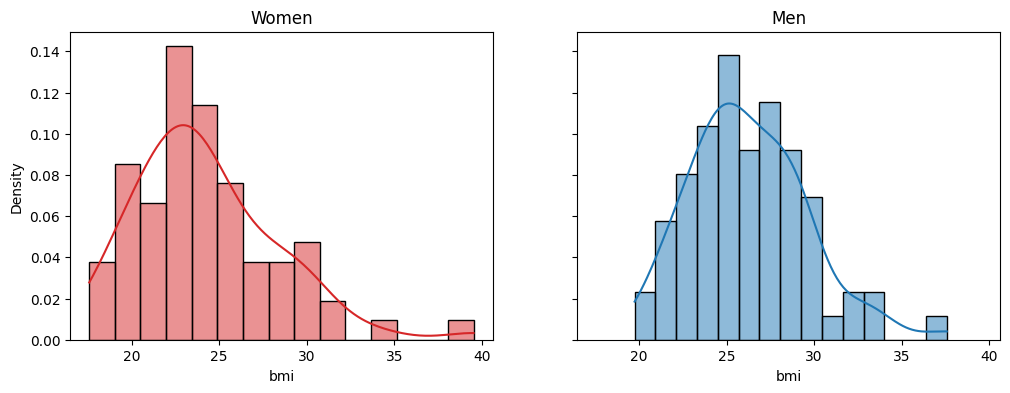

Mean BMI women: 24.22 | men: 26.27
Skewness women: 1.01 | men: 0.68


In [4]:
women = bmi[bmi["gender"] == 0]
men = bmi[bmi["gender"] == 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
sns.histplot(women["bmi"], stat="density", bins=15, kde=True, ax=axes[0], color="tab:red"); axes[0].set_title("Women")
sns.histplot(men["bmi"], stat="density", bins=15, kde=True, ax=axes[1], color="tab:blue"); axes[1].set_title("Men")
plt.show()
print(f"Mean BMI women: {women['bmi'].mean():.2f} | men: {men['bmi'].mean():.2f}")
print(f"Skewness women: {stats.skew(women['bmi']):.2f} | men: {stats.skew(men['bmi']):.2f}")
# Men have a higher center (mean 26.3 vs. 24.2), but women show the larger spread (sd 4.1 vs. 3.3) and the stronger right skew. Both are right-skewed.


## 5. Boxplot by Gender

**d) Box Plot of BMI by Gender**

- Create a box plot of BMI scores grouped by gender.
- Describe the distribution, symmetry/skewness, differences, and outliers.

**Instructions:**  
- Interpret the box plot and compare distributions.

---


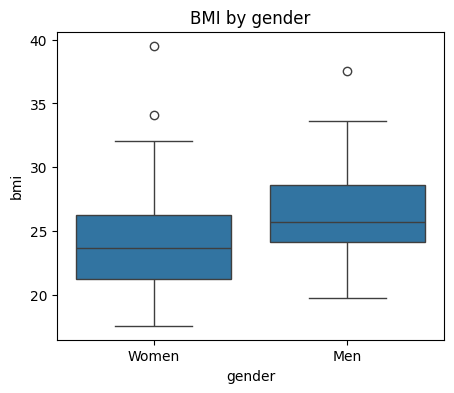

In [5]:
plt.figure(figsize=(5, 4))
sns.boxplot(data=bmi, x="gender", y="bmi")
plt.xticks([0, 1], ["Women", "Men"])
plt.title("BMI by gender")
plt.show()
# The median BMI of men is higher than that of women. Both boxes are slightly asymmetric (longer upper whisker)
# and there are a few high outliers, so both distributions are right-skewed.

## 6. Summary Statistics

**e) Key Summary Statistics for BMI**

- Calculate and report the following for everyone, women, and men:
  - Number of observations (n)
  - Sample mean (\(\bar{x}\))
  - Sample variance (\(s^2\))
  - Sample standard deviation (\(s\))
  - Lower quartile (Q1)
  - Median (Q2)
  - Upper quartile (Q3)

**Instructions:**  
- Present the summary statistics in a table.
- Discuss what additional insights are provided by the table compared to the box plot.

---


In [6]:
def summary(x):
    return pd.Series({"n": x.count(), "mean": x.mean(), "variance": x.var(), "sd": x.std(),
                      "Q1": x.quantile(.25), "median": x.median(), "Q3": x.quantile(.75)})

table = pd.DataFrame({"everyone": summary(bmi["bmi"]), "women": summary(women["bmi"]), "men": summary(men["bmi"])})
display(table.round(2))
# The table adds exact values (mean, variance, standard deviation and sample size) that a boxplot can not show.
# The boxplot shows the median, quartiles and outliers; the mean and variance tell us about the level and spread.

,everyone,women,men
n,145.00,72.00,73.00
mean,25.25,24.22,26.27
variance,14.69,16.42,11.07
sd,3.83,4.05,3.33
Q1,22.59,21.26,24.15
median,24.69,23.69,25.73
Q3,27.64,26.29,28.63


## Part 2: Missing Values, Outliers, and Bivariate EDA

## 1. Missing Values

- List the number of missing values for each variable in the dataset.
- Choose and apply appropriate strategies for handling missing values (e.g., removal, imputation).
- Justify your chosen approach.
- Show the number of observations before and after handling missing values.

In [7]:
print("Missing values per variable:")
print(bmi.isna().sum())
n_before = len(bmi)
bmi = bmi.dropna()
print(f"Observations before: {n_before}, after: {len(bmi)}")
# There are no missing values in this dataset, so no removal or imputation is necessary. If there were, removal would be
# justified when very few rows are affected, and median imputation when many rows are affected.

Missing values per variable:
height      0
weight      0
gender      0
urbanity    0
fastfood    0
bmi         0
dtype: int64
Observations before: 145, after: 145


## 2. Outlier Detection and Handling

### a) Identifying Outliers

- Use visual (boxplots, scatterplots) and statistical methods (e.g., IQR rule, z-scores) to detect outliers in BMI, height, and weight.
- List any extreme values found and discuss whether they are plausible or likely errors.



,IQR outliers,|z| > 3
bmi,2,2
height,0,0
weight,1,1


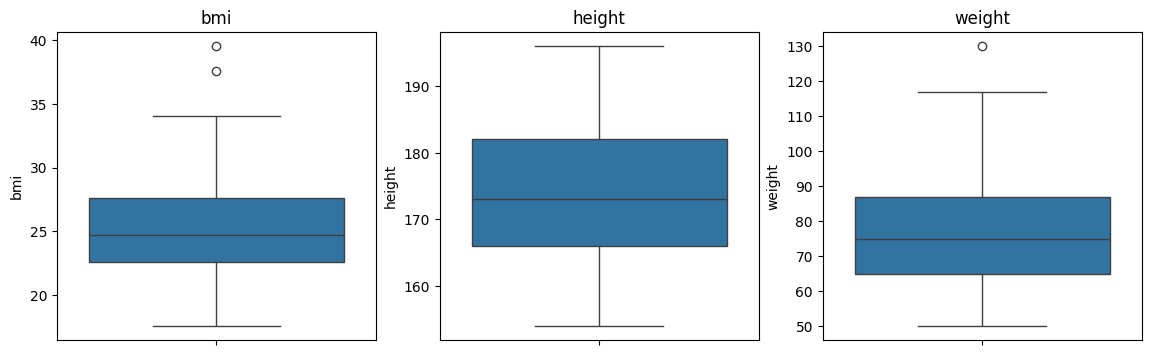

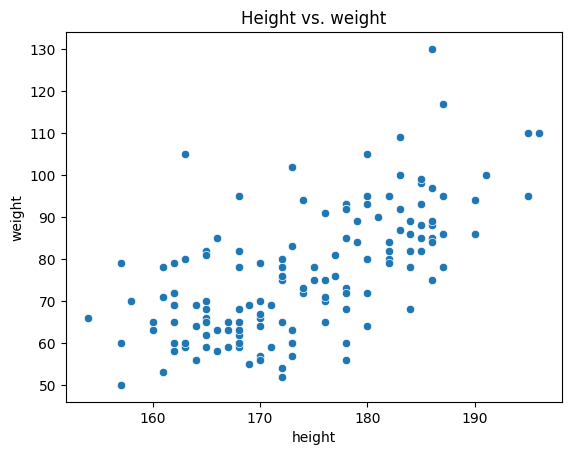

,height,weight,gender,urbanity,fastfood,bmi
144,163,105,0,3,0.0,39.519741
73,186,130,1,4,78.2,37.576598
56,173,102,0,2,6.0,34.080658
92,168,95,1,4,6.0,33.659297
124,187,117,1,5,182.5,33.458206


In [8]:
# IQR rule (1.5 x IQR) and z-scores for BMI, height and weight
outlier_report = {}
for col in ["bmi", "height", "weight"]:
    q1, q3 = bmi[col].quantile([.25, .75])
    iqr = q3 - q1
    mask_iqr = (bmi[col] < q1 - 1.5 * iqr) | (bmi[col] > q3 + 1.5 * iqr)
    z = np.abs(stats.zscore(bmi[col]))
    outlier_report[col] = {"IQR outliers": int(mask_iqr.sum()), "|z| > 3": int((z > 3).sum())}
display(pd.DataFrame(outlier_report).T)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["bmi", "height", "weight"]):
    sns.boxplot(y=bmi[col], ax=ax); ax.set_title(col)
plt.show()

sns.scatterplot(data=bmi, x="height", y="weight")
plt.title("Height vs. weight")
plt.show()
display(bmi.sort_values("bmi", ascending=False).head(5))
# The extreme values are plausible (tall or heavy people), not measurement errors: height and weight are within the
# realistic human range, so they are unusual but valid observations.


### b) Handling Outliers

- Decide how to handle detected outliers (e.g., keep, remove, or correct).
- Justify your approach and show the effect on the dataset.



In [9]:
# Decision: keep the outliers. They are plausible observations (no impossible heights/weights), and removing them
# would hide real cases of severe obesity, which is exactly what the study is about.
# To show the effect we compare the mean and standard deviation with and without the IQR outliers.
q1, q3 = bmi["bmi"].quantile([.25, .75])
iqr = q3 - q1
without = bmi[(bmi["bmi"] >= q1 - 1.5 * iqr) & (bmi["bmi"] <= q3 + 1.5 * iqr)]
print(f"With outliers: n={len(bmi)}, mean={bmi['bmi'].mean():.2f}, sd={bmi['bmi'].std():.2f}")
print(f"Without outliers: n={len(without)}, mean={without['bmi'].mean():.2f}, sd={without['bmi'].std():.2f}")

With outliers: n=145, mean=25.25, sd=3.83
Without outliers: n=143, mean=25.06, sd=3.51


## 3. Bivariate Exploratory Data Analysis (EDA)

### a) BMI and Fast Food Consumption

- Create a scatter plot of BMI vs. fast food consumption.
- Calculate and interpret the correlation coefficient.
- Comment on any patterns or associations observed.

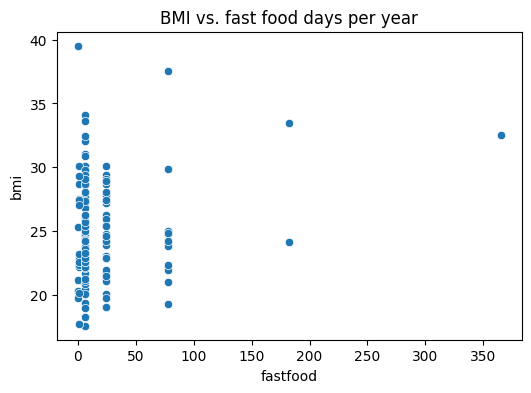

Pearson r = 0.153 | Spearman rho = 0.031


In [10]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=bmi, x="fastfood", y="bmi")
plt.title("BMI vs. fast food days per year")
plt.show()
pearson = bmi["bmi"].corr(bmi["fastfood"])
spearman = bmi["bmi"].corr(bmi["fastfood"], method="spearman")
print(f"Pearson r = {pearson:.3f} | Spearman rho = {spearman:.3f}")
# The correlation is weak (Pearson about 0.15, Spearman about 0.03). Fast food is very skewed (most people eat it 6-24 days per year, a few every day),
# so Spearman's rank correlation is the more reliable number. There is no strong association in this sample.

### b) BMI by Gender

- Use boxplots or violin plots to compare BMI distributions between genders.
- Test for significant differences (e.g., t-test or Mann-Whitney U test).

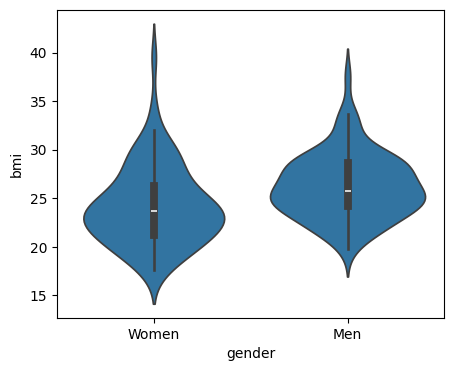

Welch t-test: t=-3.33, p=0.001133 | Mann-Whitney U: p=0.0002543
The BMI difference between women and men is statistically significant (alpha=0.05).


In [11]:
plt.figure(figsize=(5, 4))
sns.violinplot(data=bmi, x="gender", y="bmi")
plt.xticks([0, 1], ["Women", "Men"])
plt.show()
t, p_t = stats.ttest_ind(women["bmi"], men["bmi"], equal_var=False)
u, p_u = stats.mannwhitneyu(women["bmi"], men["bmi"])
print(f"Welch t-test: t={t:.2f}, p={p_t:.4g} | Mann-Whitney U: p={p_u:.4g}")
print("The BMI difference between women and men is statistically significant (alpha=0.05)." if p_t < 0.05 and p_u < 0.05
      else "No significant BMI difference between the genders at alpha=0.05.")

### c) BMI by Urbanity

- Visualize BMI across different urbanity categories using boxplots or bar plots.
- Discuss any differences or trends.

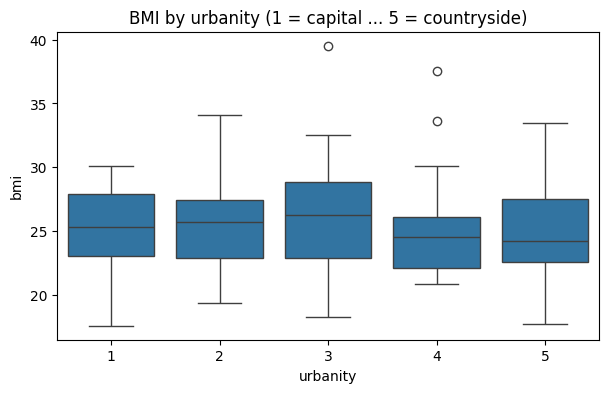

          count   mean  median
urbanity                      
1            12  25.33   25.34
2            23  25.34   25.71
3            27  26.26   26.29
4            22  25.18   24.52
5            61  24.77   24.21


In [12]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=bmi, x="urbanity", y="bmi")
plt.title("BMI by urbanity (1 = capital ... 5 = countryside)")
plt.show()
print(bmi.groupby("urbanity")["bmi"].agg(["count", "mean", "median"]).round(2))
# The medians differ only a little; the countryside group (5) has the lowest median BMI, but there is no clear trend
# with city size and some groups are small (12-27 people), so the differences may be sampling variation.

### d) Additional Bivariate Relationships

- Explore other pairs of variables as relevant (e.g., weight vs. height, fast food vs. gender).
- Use appropriate plots and statistics.

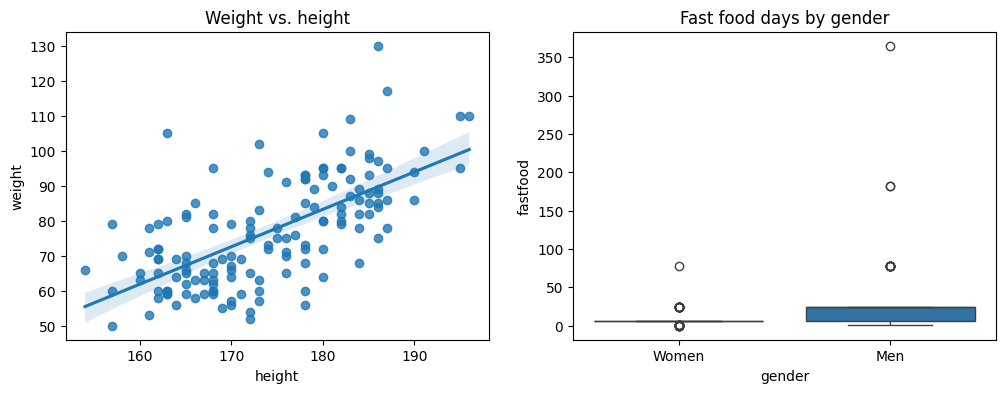

Correlation height/weight: 0.655
         mean  median
gender               
0       10.03     6.0
1       31.89    24.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=bmi, x="height", y="weight", ax=axes[0]); axes[0].set_title("Weight vs. height")
sns.boxplot(data=bmi, x="gender", y="fastfood", ax=axes[1]); axes[1].set_title("Fast food days by gender")
axes[1].set_xticks([0, 1], ["Women", "Men"])
plt.show()
print("Correlation height/weight:", round(bmi["height"].corr(bmi["weight"]), 3))
print(bmi.groupby("gender")["fastfood"].agg(["mean", "median"]).round(2))
# Taller people weigh more (strong positive correlation, mostly a gender effect). Men report clearly more fast food days (mean about 32 vs. 10 days per year).

## 4. Summary

- Summarize the key findings from your missing value analysis, outlier handling, and bivariate EDA.
- Discuss how these steps improve the quality and reliability of your subsequent analyses.

In [14]:
# Summary:
# - No missing values, so all 145 observations could be used.
# - The IQR / z-score checks found a few extreme BMI values, but they are plausible, so they were kept.
# - BMI is right-skewed; men have a higher BMI than women (significant difference).
# - Fast food consumption is only weakly related to BMI, and urbanity shows no clear trend.
# Checking missing values and outliers first makes the later statistics (means, correlations, tests) more reliable,
# because we know that they are not driven by errors, and it tells us which statistics (median, Spearman) are robust.

Happy Coding .... ;) 